In [20]:
import geopandas as gpd
import pandas as pd
import sys
import matplotlib.pyplot as plt
from scipy import stats
from matplotlib.colors import PowerNorm

# # ----------------------------------------------------------------------------
# # 0. SETUP
# # ----------------------------------------------------------------------------
TARGET = "prop_floodable_area_flooded" # "10cm_area"
GROUP_COL = None          # e.g. "catchment_id" / "cell_id" -- STRONGLY recommended if spatial/temporal autocorrelation
SEED = 42

from PrepDataFunctions import *
#
sys.path.insert(1, '../../ProcessEvents')
from config import CATCHMENTS

### Get data

In [2]:
rainfall_events_all_df = prep_for_modelling(f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo_and_temporal.pkl", 
                        remove_events_with_zero_flooding = False)

### Join to spatial information

In [3]:
regions_shp = "/scratch/hydro5/users/la17355/FUTURE-FLOOD/Results/Pluvial/v4/#ss/plots/most_exposed_events_visualisation/by_region/ukcp18-uk-land-region-hires.shp"
regions_df = gpd.read_file(regions_shp)
regions_df["region_geometry"] = regions_df.geometry

catchments_df = CATCHMENTS
catchments_df["catchment_geometry"] = catchments_df.geometry

# Event points
rainfall_events_all_df = gpd.GeoDataFrame(rainfall_events_all_df,
                        geometry=gpd.points_from_xy(rainfall_events_all_df["x_coord"], rainfall_events_all_df["y_coord"]), 
                                          crs=regions_df.crs)

# Remove old sjoin columns if this dataframe has been joined before
rainfall_events_all_df = rainfall_events_all_df.drop(
    columns=["index_right", "geo_region", "region_geometry", "HA_NAME", "catchment_geometry"], errors="ignore")

# Join regions
rainfall_events_all_df = gpd.sjoin(rainfall_events_all_df, regions_df[["geo_region", "region_geometry", "geometry"]],
    how="left", predicate="within")

# Drop index_right before the next sjoin, or geopandas will error on the clash
rainfall_events_all_df = rainfall_events_all_df.drop(columns=["index_right"], errors="ignore")

# Join catchments
rainfall_events_all_df = gpd.sjoin(rainfall_events_all_df, catchments_df[["HA_NAME", "catchment_geometry", "geometry"]],
    how="left", predicate="within")

rainfall_events_all_df = rainfall_events_all_df.drop(columns=["index_right"], errors="ignore")

### Find catchment level values

In [13]:
critical_durs = []
max_corrs = []
avg_event_length =[]

for catchment_name in np.unique(rainfall_events_all_df['HA_NAME']):
    # Get data for this catchment
    one_catchment = rainfall_events_all_df[rainfall_events_all_df['HA_NAME'] ==catchment_name]
    # Get average length of event
    mean_len = np.nanmean(one_catchment['length_of_active_rain'])
    # Find 'critical duration'
    max_corr = 0
    critical_duration = ''
    for var in ["max_precip", 'max_2h', "max_3h", "max_6h", "max_12h", "max_16h", "total_acc"]:
        res = stats.spearmanr(one_catchment['10cm_area'], one_catchment[var])
        if res.statistic > max_corr and res.pvalue <0.05:
            max_corr = res.statistic
            critical_duration = var
    critical_durs.append(critical_duration)
    max_corrs.append(max_corr)
    avg_event_length.append(mean_len)

# convert to dataframe
test = pd.DataFrame({'HA_NAME': np.unique(rainfall_events_all_df['HA_NAME']),
              'critical_dur' : critical_durs, 'max_corr': max_corrs, 'avg_event_len': avg_event_length})

test = catchments_df.merge(test, on='HA_NAME')    

### Create plot

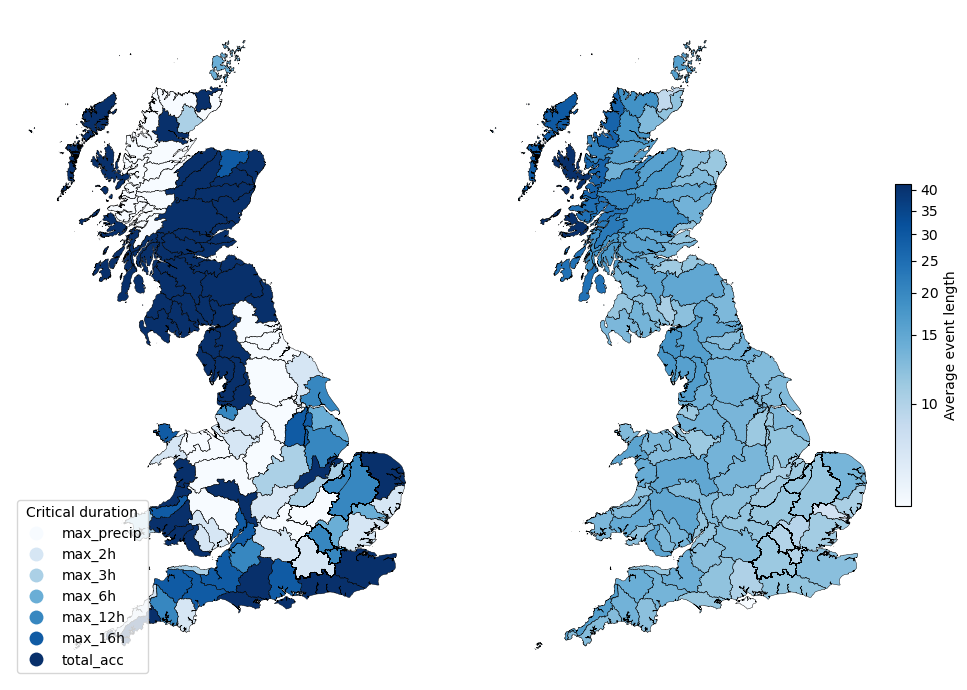

In [28]:
duration_order = ['max_precip', 'max_2h', 'max_3h', 'max_6h', 'max_12h', 'max_16h', 'total_acc']

test['critical_dur'] = pd.Categorical(test['critical_dur'], categories=duration_order, ordered=True)

fig, axs = plt.subplots(ncols=2, figsize=(10, 7))

test.plot(column='critical_dur', categorical=True, legend=True, cmap='Blues', ax=axs[0],
          edgecolor='black', linewidth=0.3, legend_kwds={'title': 'Critical duration', 'loc': 'lower left'})
axs[0].set_axis_off()

im = test.plot(column='avg_event_len', legend=False, cmap='Blues', norm=PowerNorm(gamma=0.4),
               ax=axs[1], edgecolor='black', linewidth=0.3)
axs[1].set_axis_off()

cbar = fig.colorbar(im.collections[0], ax=axs[1], shrink=0.8, fraction=0.035, pad=0.02)
cbar.set_label('Average event length')

plt.tight_layout()
plt.show()